<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Altermagnetic_Domain_Wall_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
try:
    import google.colab
except ImportError:
    pass
else:
    !uv pip install mumaxplus pillow

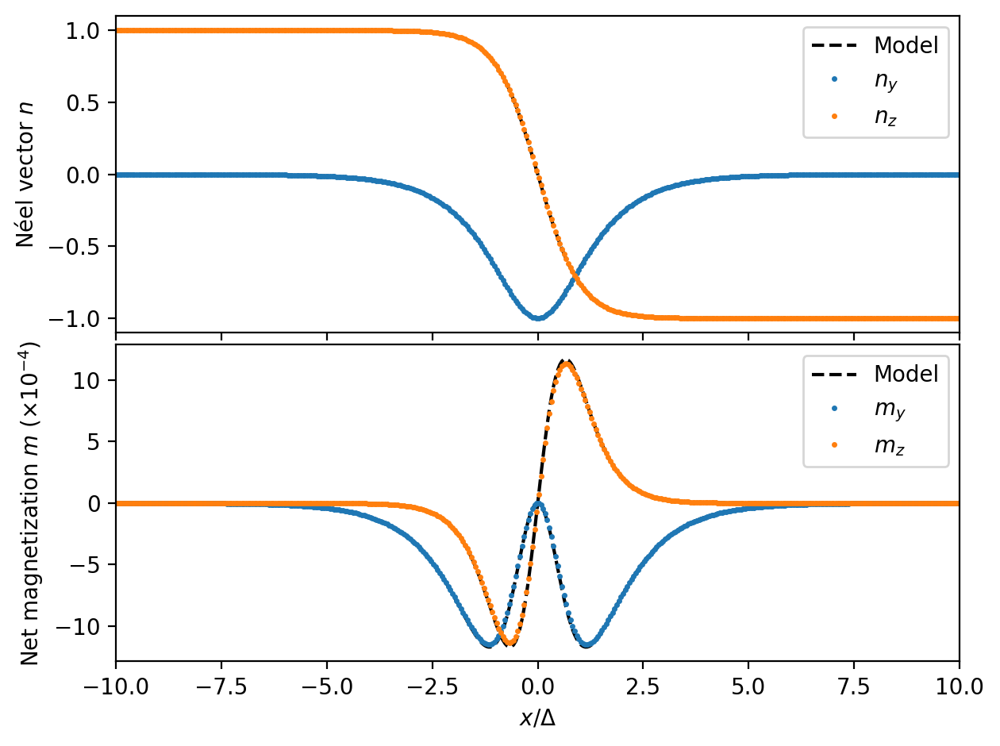

In [4]:
import matplotlib.pyplot as plt
import numpy as np

from mumaxplus import Altermagnet, Grid, World

plt.rcParams['figure.dpi'] = 200

# ----------- Material and simulation parameters -----------

cs = 0.5e-9
a  = 0.35e-9

Ms  = 2.9e5
K   = 2e5
A1  = 25e-12
A2  = 15e-12
A0  = -5e-13
A12 = A0/2

length = 256e-9

# ----------- Create altermagnet -----------

Nx = int(length / cs)
world  = World((cs, cs, cs))
grid   = Grid((Nx, 1, 1))
magnet = Altermagnet(world, grid)

# ----------- Set parameters -----------

magnet.msat  = Ms
magnet.alpha = 0.01

magnet.ku1   = K
magnet.anisU = (0, 0, 1)

magnet.afmex_nn   = A12
magnet.afmex_cell = A0
magnet.latcon     = a

magnet.alterex_1 = A1 # first exchange matrix eigenvalue
magnet.alterex_2 = A2 # second exchange matrix eigenvalue
magnet.alterex_angle = 0 # exchange frame of reference aligns with the simulation grid

# ----------- Create a two-domain state -----------

dw_idx = 10 # initial guess of DW width (in cells)
m = np.zeros(magnet.sub1.magnetization.shape)
m[2, :, :,              0:Nx//2 - dw_idx] = 1   # Left domain
m[1, :, :, Nx//2 - dw_idx:Nx//2 + dw_idx] = -1  # Domain wall
m[2, :, :, Nx//2 + dw_idx:] = -1                # Right domain

magnet.sub1.magnetization =  m
magnet.sub2.magnetization = -m

# minimize to ground state
magnet.minimize()

# ----------- Plot Néel and net magnetization profiles -----------
fig, axs = plt.subplots(2, 1, sharex=True)
scale_net = 1e4
# Theoretical profiles
dw = np.sqrt(((A1+A2) - A12) / (2*K)) # Theoretical DW width
t = np.linspace(-Nx*cs/2, Nx*cs/2, Nx) / dw

# --- NEEL ---
theta = 2*np.arctan(np.exp(t))
axs[0].plot(t, np.cos(theta),  'k--', label="Model")
axs[0].plot(t, np.sin(-theta), 'k--')

# --- NET ---
Han = 2 * K / Ms
Hex = -8 * A0 / ( Ms * (a**2))
prefactor = (Han/Hex) * (A1-A2) / ((A1+A2) - A12)

theory_y = -prefactor * np.sinh(t)**2 / np.cosh(t)**3
theory_z =  prefactor * np.sinh(t)   /  np.cosh(t)**3
axs[1].plot(t, scale_net * theory_y, 'k--', label="Model")
axs[1].plot(t, scale_net * theory_z, 'k--')

# Simulated profiles
ms = 3

# --- NEEL ---
neel = magnet.neel_vector()[:, 0, 0, :]
axs[0].plot(t, neel[1], '.', label=r"$n_y$", markersize=ms)
axs[0].plot(t, neel[2], '.', label=r"$n_z$", markersize=ms)

# --- NET ---
net = 0.5 * (magnet.sub1.magnetization() + magnet.sub2.magnetization())[:, 0, 0, :]
axs[1].plot(t, scale_net * net[1], '.', label=r"$m_y$", markersize=ms)
axs[1].plot(t, scale_net * net[2], '.', label=r"$m_z$", markersize=ms)

# --- Plotter stuff ---
axs[1].set_xlabel(r"$x/\Delta$")
axs[1].set_ylabel(r"Net magnetization $m$ ($\times 10^{-4}$)")
axs[0].set_ylabel(r"Néel vector $n$")
axs[0].set_xlim(-10, 10)
axs[0].legend()
axs[1].legend()
plt.tight_layout(h_pad=0.2)
plt.show()

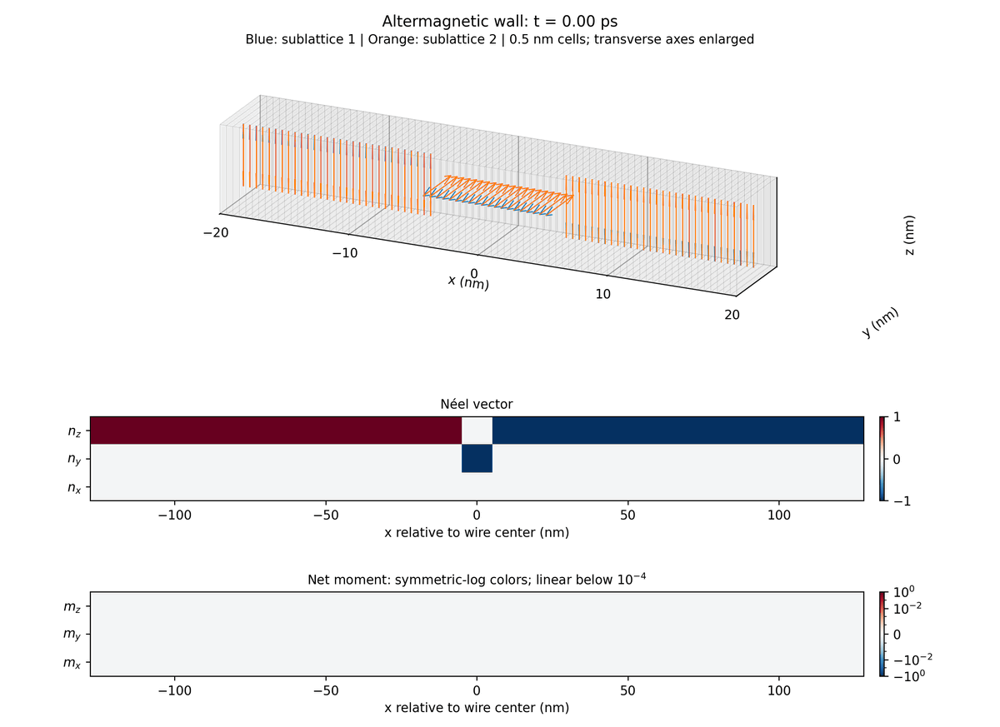

In [5]:
"""This script animates physical wall dynamics after the preceding cell."""

import gc
from io import BytesIO

from IPython.display import Image as DisplayImage, display
from matplotlib.colors import SymLogNorm
from PIL import GifImagePlugin, Image as PILImage

GIF_FPS = 12
plt.rcParams.update({"font.family": "DejaVu Sans", "font.weight": "normal",
                     "axes.titleweight": "normal"})

# --- Restart from the existing initial two-domain array ---
magnet.sub1.magnetization = np.asarray(m, dtype=np.float32)
magnet.sub2.magnetization = -np.asarray(m, dtype=np.float32)
world.timesolver.time = 0
frame_times = np.linspace(0, 25e-12, 121)
cs_nm = cs * 1e9
x_nm = (np.arange(Nx) - (Nx - 1) / 2) * cs_nm
edges = (np.arange(Nx + 1) - Nx / 2) * cs_nm
selected = np.flatnonzero(np.abs(x_nm) <= 2 * dw * 1e9)
cross = np.array([-0.5, 0.5]) * cs_nm

# --- Create a fixed 3D view and two component heatmaps ---
fig = plt.figure(figsize=(11, 8), dpi=250)
layout = fig.add_gridspec(3, 1, height_ratios=(3, 1, 1))
ax3d = fig.add_subplot(layout[0], projection="3d")
mesh = np.meshgrid(edges[selected[0]:selected[-1] + 2], cross, cross,
                   indexing="ij")
ax3d.voxels(*mesh, np.ones((len(selected), 1, 1), dtype=bool),
            facecolors=(0.7, 0.7, 0.7, 0.025),
            edgecolors=(0.5, 0.5, 0.5, 0.2), linewidth=0.25,
            clip_on=False)
ax3d.set(xlim=(edges[selected[0]], edges[selected[-1] + 1]),
         ylim=cross, zlim=cross, xlabel="x (nm)",
         ylabel="y (nm)", zlabel="z (nm)")
ax3d.set_yticks([])
ax3d.set_zticks([])
ax3d.set_box_aspect((12, 2, 2), zoom=2.25)
ax3d.set_proj_type("ortho")
ax3d.view_init(elev=20, azim=-65)
arrows = []

images = []
for row, (title, labels) in enumerate((
    ("Néel vector", (r"$n_x$", r"$n_y$", r"$n_z$")),
    (r"Net moment: symmetric-log colors; linear below $10^{-4}$",
     (r"$m_x$", r"$m_y$", r"$m_z$")),
), start=1):
    ax = fig.add_subplot(layout[row])
    options = {"vmin": -1, "vmax": 1} if row == 1 else {
        "norm": SymLogNorm(linthresh=1e-4, vmin=-1, vmax=1, base=10)
    }
    image = ax.imshow(np.zeros((3, Nx), dtype=np.float32), origin="lower",
                      extent=(edges[0], edges[-1], -0.5, 2.5),
                      aspect="auto", interpolation="nearest",
                      cmap="RdBu_r", **options)
    ax.set_yticks((0, 1, 2), labels=labels)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("x relative to wire center (nm)")
    ticks = (-1, 0, 1) if row == 1 else (-1, -1e-2, 0, 1e-2, 1)
    fig.colorbar(image, ax=ax, fraction=0.025, pad=0.02, ticks=ticks)
    images.append(image)

timestamp = fig.suptitle("", y=0.98)
fig.text(0.5, 0.94, "Blue: sublattice 1 | Orange: sublattice 2 | "
         f"{cs_nm:g} nm cells; transverse axes enlarged", ha="center")
fig.subplots_adjust(left=0.09, right=0.90, bottom=0.07, top=0.90,
                    hspace=0.65)

# --- Encode each frame immediately using one unsigned 8-bit palette ---
palette_rgb = np.vstack((
    255 * plt.get_cmap("RdBu_r")(np.linspace(0, 1, 224))[:, :3],
    np.repeat(np.linspace(0, 255, 30)[:, None], 3, axis=1),
    [[31, 119, 180], [255, 127, 14]],
)).round().astype(np.uint8)
palette = PILImage.new("P", (1, 1))
palette.putpalette(palette_rgb.ravel().tolist())
gif_buffer = BytesIO()

for start in range(0, len(frame_times), 8):
    batch = world.timesolver.solve(frame_times[start:start + 8], {
        "m1": magnet.sub1.magnetization,
        "m2": magnet.sub2.magnetization,
        "n": magnet.neel_vector,
    })
    for offset, frame_time in enumerate(batch["time"]):
        frame_index = start + offset
        sub1 = np.asarray(batch["m1"][offset], dtype=np.float32)
        sub2 = np.asarray(batch["m2"][offset], dtype=np.float32)
        n_frame = np.asarray(batch["n"][offset], dtype=np.float32)
        net_frame = np.float32(0.5) * (sub1 + sub2)
        images[0].set_data(n_frame[:, 0, 0, :])
        images[1].set_data(net_frame[:, 0, 0, :])

        for arrow in arrows:
            arrow.remove()
        arrows.clear()
        for field, color in ((sub1, "tab:blue"), (sub2, "tab:orange")):
            vectors = field[:, 0, 0, :][:, selected]
            arrows.append(ax3d.quiver(
                x_nm[selected], np.zeros(len(selected)),
                np.zeros(len(selected)), *vectors,
                length=0.7 * cs_nm, normalize=False, pivot="middle",
                arrow_length_ratio=0.25, color=color, linewidth=0.8,
                clip_on=False,
            ))
        timestamp.set_text(
            f"Altermagnetic wall: t = {frame_time * 1e12:.2f} ps"
        )
        fig.canvas.draw()
        with PILImage.fromarray(
            np.asarray(fig.canvas.buffer_rgba())[:, :, :3]
        ) as rgb:
            rgb.thumbnail((1200, 900), PILImage.Resampling.LANCZOS)
            gif_frame = rgb.quantize(palette=palette,
                                     dither=PILImage.Dither.NONE)
        if frame_index == 0:
            for block in GifImagePlugin.getheader(
                gif_frame, info={"loop": 0, "optimize": False}
            )[0]:
                gif_buffer.write(block)
        delay_ms = 10 * (round((frame_index + 1) * 100 / GIF_FPS)
                         - round(frame_index * 100 / GIF_FPS))
        for block in GifImagePlugin.getdata(
            gif_frame, duration=delay_ms, disposal=1
        ):
            gif_buffer.write(block)
        gif_frame.close()

    # Release CPU snapshots; mumaxplus manages its own CUDA memory pool.
    del batch, sub1, sub2, n_frame, net_frame, field, vectors
    gc.collect()

gif_buffer.write(b";")
gif_bytes = gif_buffer.getvalue()
gif_buffer.close()
palette.close()
plt.close(fig)
del fig, layout, ax3d, ax, images, image, timestamp, arrows, arrow, mesh
gc.collect()
display(DisplayImage(data=gif_bytes, format="gif"))